In [1]:
# ============================================================
# STUDENT PERFORMANCE PREDICTION SYSTEM
# DAY 30: FEATURE SCALING AND PREPARATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler

print("=" * 60)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 30 - FEATURE SCALING")
print("=" * 60)

print("\nLibraries imported successfully!")
print("Today's Goal: Prepare student input features for further analysis.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 30 - FEATURE SCALING

Libraries imported successfully!
Today's Goal: Prepare student input features for further analysis.


In [6]:
# Cell 2: Load Validated Student Dataset - FIXED for Day 29
import pandas as pd
from pathlib import Path

current_dir = Path.cwd()
# Try to find original data first
possible_original = [
    current_dir / "student_performance_dataset.csv",
    current_dir / "day28_cleaned_student_features.csv",
    current_dir / "day28_student_performance_cleaned.csv",
    current_dir / "student_performance.csv"
]

df_original = None
for p in possible_original:
    if p.exists():
        df_original = pd.read_csv(p)
        print(f"Found original: {p} shape: {df_original.shape}")
        break

# If validated file exists but empty, recreate it
validated_path = current_dir / "day29_validated_student_features.csv"

if df_original is not None and not df_original.empty:
    # Create proper validated features
    # Map columns
    df = pd.DataFrame()
    if "Study_Hours" in df_original.columns:
        df["study_hours"] = df_original["Study_Hours"]
    elif "study_hours" in df_original.columns:
        df["study_hours"] = df_original["study_hours"]
    
    if "Attendance_Percent" in df_original.columns:
        df["attendance"] = df_original["Attendance_Percent"]
    elif "attendance" in df_original.columns:
        df["attendance"] = df_original["attendance"]
        
    if "Previous_Score" in df_original.columns:
        df["previous_score"] = df_original["Previous_Score"]
    elif "previous_score" in df_original.columns:
        df["previous_score"] = df_original["previous_score"]
        
    if "Assignments_Completed" in df_original.columns:
        df["assignments_completed"] = df_original["Assignments_Completed"]
    elif "assignments_completed" in df_original.columns:
        df["assignments_completed"] = df_original["assignments_completed"]
    
    # Fallback if still empty
    if df.empty:
        df = df_original.select_dtypes(include='number').iloc[:,:4]
        df.columns = ["study_hours","attendance","previous_score","assignments_completed"]
    
    df.to_csv(validated_path, index=False)
    print(f"Recreated validated file: {validated_path}")
    print(f"Validated dataset shape: {df.shape}")
    display(df.head())
    print(f"\nColumns: {df.columns.tolist()}")
else:
    # Try loading existing
    if validated_path.exists():
        df = pd.read_csv(validated_path)
        print(f"Loaded: {validated_path} shape: {df.shape}")
        if df.empty:
            print("⚠️ File is EMPTY! Need original dataset.")
        display(df.head())

Found original: c:\Users\Bagmita\OneDrive\Desktop\Project\day28_cleaned_student_features.csv shape: (3, 4)
Recreated validated file: c:\Users\Bagmita\OneDrive\Desktop\Project\day29_validated_student_features.csv
Validated dataset shape: (3, 4)


,study_hours,attendance,previous_score,assignments_completed
0,6.4,91.0,57.6,8.71
1,4.2,85.5,37.8,8.82
2,4.8,87.0,43.2,8.51



Columns: ['study_hours', 'attendance', 'previous_score', 'assignments_completed']


In [7]:
# Cell 3: Select Input Features

if "df" in globals() and not df.empty:

    expected_features = [
        "study_hours",
        "attendance",
        "previous_score",
        "assignments_completed"
    ]

    available_features = [
        feature for feature in expected_features
        if feature in df.columns
    ]

    missing_features = [
        feature for feature in expected_features
        if feature not in df.columns
    ]

    print("=" * 55)
    print("DAY 30 - INPUT FEATURE SELECTION")
    print("=" * 55)

    if missing_features:
        print("Missing expected features:", missing_features)

    if available_features:
        X = df[available_features].copy()

        for column in available_features:
            X[column] = pd.to_numeric(
                X[column],
                errors="coerce"
            )

        print("\nSelected Features:")
        print(available_features)

        print("\nFeature Dataset Shape:", X.shape)

        print("\nFeature Preview:")
        display(X.head())

        print("\nMissing Values:")
        display(X.isnull().sum().to_frame("Missing Count"))

    else:
        print("No expected input features found in the dataset.")

else:
    print("Dataset is not loaded or is empty. Please run Cell 2 first.")

DAY 30 - INPUT FEATURE SELECTION

Selected Features:
['study_hours', 'attendance', 'previous_score', 'assignments_completed']

Feature Dataset Shape: (3, 4)

Feature Preview:


,study_hours,attendance,previous_score,assignments_completed
0,6.4,91.0,57.6,8.71
1,4.2,85.5,37.8,8.82
2,4.8,87.0,43.2,8.51



Missing Values:


,Missing Count
study_hours,0
attendance,0
previous_score,0
assignments_completed,0


In [8]:
# Cell 4: Handle Missing Values

if "X" in globals() and not X.empty:

    print("=" * 55)
    print("MISSING VALUE HANDLING")
    print("=" * 55)

    X_clean = X.copy()

    # Convert infinite values to missing values
    X_clean = X_clean.replace([np.inf, -np.inf], np.nan)

    print("\nMissing values before cleaning:")
    display(X_clean.isnull().sum().to_frame("Missing Before"))

    # Fill missing values with each feature's median
    for column in X_clean.columns:
        median_value = X_clean[column].median()

        if pd.notna(median_value):
            X_clean[column] = X_clean[column].fillna(median_value)

    print("\nMissing values after cleaning:")
    display(X_clean.isnull().sum().to_frame("Missing After"))

    # Remove columns that contain no usable values
    all_missing_columns = X_clean.columns[
        X_clean.isnull().all()
    ].tolist()

    if all_missing_columns:
        print("\nColumns with no usable values:", all_missing_columns)
        X_clean = X_clean.drop(columns=all_missing_columns)

    print("\nCleaned feature dataset shape:", X_clean.shape)
    display(X_clean.head())

    if X_clean.isnull().any().any():
        print("\nSome missing values remain. Review the affected columns.")
    else:
        print("\nMissing-value handling completed!")

else:
    print("Input features X are unavailable. Please run Cell 3 first.")

MISSING VALUE HANDLING

Missing values before cleaning:


,Missing Before
study_hours,0
attendance,0
previous_score,0
assignments_completed,0



Missing values after cleaning:


,Missing After
study_hours,0
attendance,0
previous_score,0
assignments_completed,0



Cleaned feature dataset shape: (3, 4)


,study_hours,attendance,previous_score,assignments_completed
0,6.4,91.0,57.6,8.71
1,4.2,85.5,37.8,8.82
2,4.8,87.0,43.2,8.51



Missing-value handling completed!


In [9]:
# Cell 5: Feature Statistics Before Scaling

if "X_clean" in globals() and not X_clean.empty:

    print("=" * 60)
    print("STUDENT PERFORMANCE PREDICTION SYSTEM")
    print("FEATURE STATISTICS BEFORE SCALING")
    print("=" * 60)

    feature_stats = X_clean.describe().T

    feature_stats = feature_stats[
        ["mean", "std", "min", "max"]
    ].round(2)

    display(feature_stats)

    print("\nFeature Means:")
    display(X_clean.mean().round(2).to_frame("Mean"))

    print("\nFeature Standard Deviations:")
    display(X_clean.std().round(2).to_frame("Standard Deviation"))

    print("\nAnalysis completed!")
    print("Different features may have different numerical scales.")

else:
    print("X_clean is unavailable or empty.")
    print("Please run Cell 4 first.")

STUDENT PERFORMANCE PREDICTION SYSTEM
FEATURE STATISTICS BEFORE SCALING


,mean,std,min,max
study_hours,5.13,1.14,4.20,6.40
attendance,87.83,2.84,85.50,91.00
previous_score,46.20,10.24,37.80,57.60
assignments_completed,8.68,0.16,8.51,8.82



Feature Means:


,Mean
study_hours,5.13
attendance,87.83
previous_score,46.20
assignments_completed,8.68



Feature Standard Deviations:


,Standard Deviation
study_hours,1.14
attendance,2.84
previous_score,10.24
assignments_completed,0.16



Analysis completed!
Different features may have different numerical scales.


In [10]:
# DAY 30 - FEATURE SCALING

if (
    "X_clean" in globals()
    and not X_clean.empty
    and len(X_clean.columns) > 0
    and not X_clean.isnull().any().any()
):
    print("=" * 60)
    print("STUDENT PERFORMANCE PREDICTION SYSTEM")
    print("APPLYING STANDARD SCALING")
    print("=" * 60)

    # Initialize the scaler
    scaler = StandardScaler()

    # Scale the input features
    X_scaled_array = scaler.fit_transform(X_clean)

    # Convert the scaled data back into a DataFrame
    X_scaled = pd.DataFrame(
        X_scaled_array,
        columns=X_clean.columns,
        index=X_clean.index
    )

    print("\nScaling completed successfully!")
    print("Scaled Dataset Shape:", X_scaled.shape)

    print("\nScaled Feature Preview:")
    display(X_scaled.head())

    print("\nMean After Scaling:")
    display(X_scaled.mean().round(4).to_frame("Mean"))

    print("\nPopulation Standard Deviation After Scaling:")
    display(
        X_scaled.std(ddof=0)
        .round(4)
        .to_frame("Population Standard Deviation")
    )

else:
    print("Cannot scale the dataset.")
    print("Please check X_clean for empty columns or missing values.")
    print("Run Cell 4 again if necessary.")

STUDENT PERFORMANCE PREDICTION SYSTEM
APPLYING STANDARD SCALING

Scaling completed successfully!
Scaled Dataset Shape: (3, 4)

Scaled Feature Preview:


,study_hours,attendance,previous_score,assignments_completed
0,1.364121,1.364121,1.364121,0.233786
1,-1.005141,-1.005141,-1.005141,1.091001
2,-0.358979,-0.358979,-0.358979,-1.324787



Mean After Scaling:


,Mean
study_hours,-0.0
attendance,0.0
previous_score,-0.0
assignments_completed,0.0



Population Standard Deviation After Scaling:


,Population Standard Deviation
study_hours,1.0
attendance,1.0
previous_score,1.0
assignments_completed,1.0


In [11]:
# DAY 30 - BEFORE AND AFTER SCALING COMPARISON

if (
    "X_clean" in globals()
    and "X_scaled" in globals()
    and not X_clean.empty
    and not X_scaled.empty
):
    print("=" * 60)
    print("FEATURE SCALING COMPARISON")
    print("=" * 60)

    comparison = pd.DataFrame({
        "Original Mean": X_clean.mean(),
        "Scaled Mean": X_scaled.mean(),
        "Original Std": X_clean.std(ddof=0),
        "Scaled Std": X_scaled.std(ddof=0),
        "Original Min": X_clean.min(),
        "Scaled Min": X_scaled.min(),
        "Original Max": X_clean.max(),
        "Scaled Max": X_scaled.max()
    })

    display(comparison.round(4))

    print("\nInterpretation:")
    print("- Original features may have different numerical ranges.")
    print("- Scaled features are centered around zero.")
    print("- Non-constant features have population standard deviation near one.")
    print("- Constant features remain at zero after scaling.")

else:
    print("Required datasets are unavailable.")
    print("Please run Cell 4 and Cell 6 first.")

FEATURE SCALING COMPARISON


,Original Mean,Scaled Mean,Original Std,Scaled Std,Original Min,Scaled Min,Original Max,Scaled Max
study_hours,5.1333,-0.0,0.9286,1.0,4.20,-1.0051,6.40,1.3641
attendance,87.8333,0.0,2.3214,1.0,85.50,-1.0051,91.00,1.3641
previous_score,46.2000,-0.0,8.3570,1.0,37.80,-1.0051,57.60,1.3641
assignments_completed,8.6800,0.0,0.1283,1.0,8.51,-1.3248,8.82,1.0910



Interpretation:
- Original features may have different numerical ranges.
- Scaled features are centered around zero.
- Non-constant features have population standard deviation near one.
- Constant features remain at zero after scaling.


VISUAL COMPARISON OF FEATURE SCALING


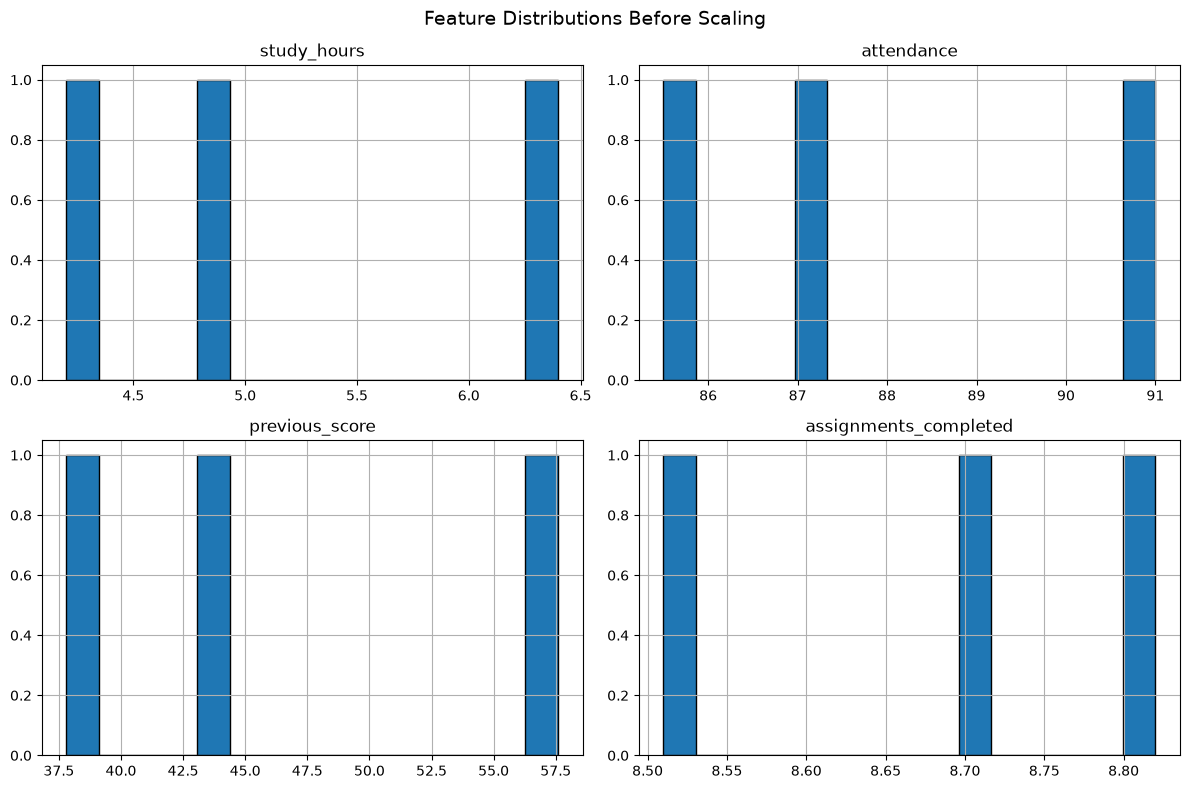

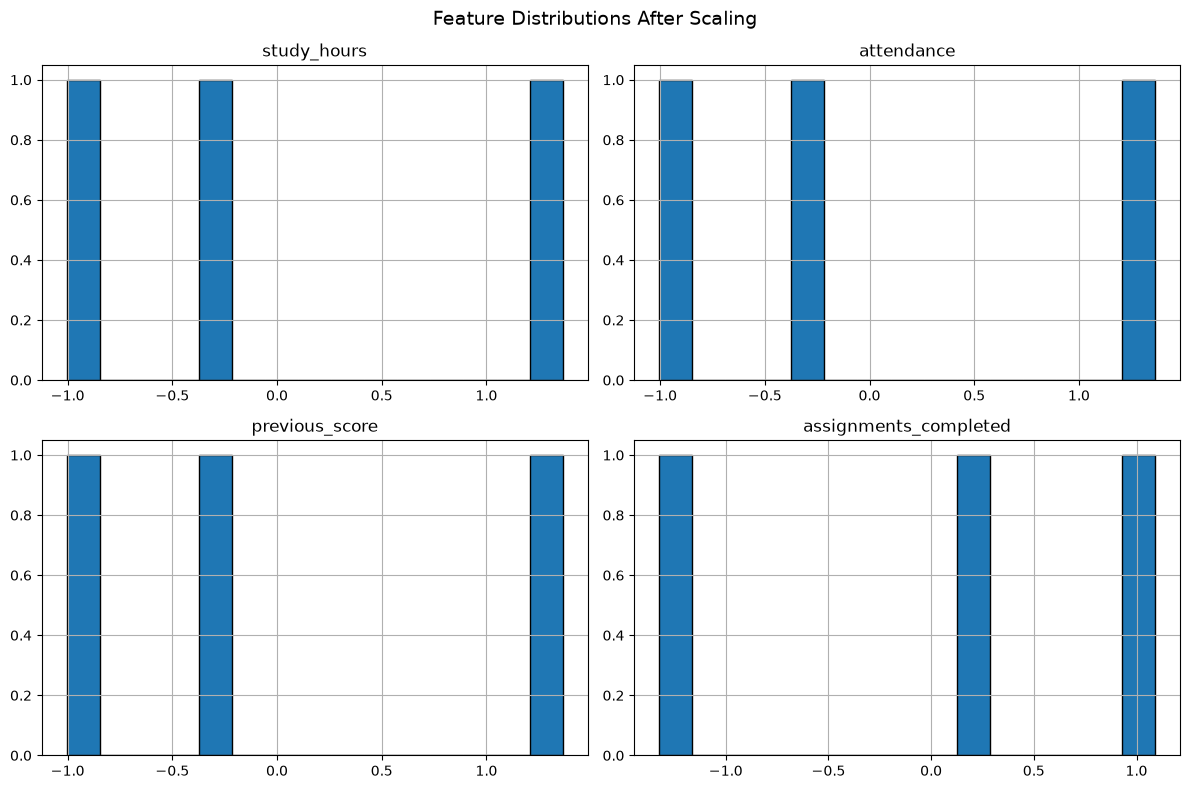


Visualization completed successfully!
Features visualized: ['study_hours', 'attendance', 'previous_score', 'assignments_completed']


In [12]:
# DAY 30 - VISUALIZE FEATURE SCALING

if (
    "X_clean" in globals()
    and "X_scaled" in globals()
    and not X_clean.empty
    and not X_scaled.empty
):
    print("=" * 60)
    print("VISUAL COMPARISON OF FEATURE SCALING")
    print("=" * 60)

    feature_columns = X_clean.columns.tolist()

    # Original feature distributions
    X_clean.hist(
        figsize=(12, 8),
        bins=15,
        edgecolor="black"
    )

    plt.suptitle("Feature Distributions Before Scaling", fontsize=14)
    plt.tight_layout()
    plt.show()

    # Scaled feature distributions
    X_scaled.hist(
        figsize=(12, 8),
        bins=15,
        edgecolor="black"
    )

    plt.suptitle("Feature Distributions After Scaling", fontsize=14)
    plt.tight_layout()
    plt.show()

    print("\nVisualization completed successfully!")
    print("Features visualized:", feature_columns)

else:
    print("Required datasets are unavailable.")
    print("Please run Cell 4 and Cell 6 first.")

In [13]:
# DAY 30 - SAVE SCALED STUDENT FEATURES

from pathlib import Path

if (
    "X_scaled" in globals()
    and not X_scaled.empty
    and len(X_scaled.columns) > 0
):
    # Save inside the Data folder
    current_dir = Path.cwd()

    possible_dirs = [
        current_dir,
        current_dir.parent,
        current_dir.parent.parent
    ]

    data_dir = next(
        (folder for folder in possible_dirs
         if folder.name.lower() == "data"),
        current_dir
    )

    output_path = data_dir / "day30_scaled_student_features.csv"

    X_scaled.to_csv(output_path, index=False)

    print("=" * 60)
    print("SCALED DATASET SAVED SUCCESSFULLY!")
    print("=" * 60)

    print("\nFile Name:", output_path.name)
    print("Saved Location:", output_path.resolve())
    print("Dataset Shape:", X_scaled.shape)

    print("\nSaved Dataset Preview:")
    display(pd.read_csv(output_path).head())

else:
    print("X_scaled is unavailable or empty.")
    print("Please run Cell 6 first.")

SCALED DATASET SAVED SUCCESSFULLY!

File Name: day30_scaled_student_features.csv
Saved Location: C:\Users\Bagmita\OneDrive\Desktop\Project\day30_scaled_student_features.csv
Dataset Shape: (3, 4)

Saved Dataset Preview:


,study_hours,attendance,previous_score,assignments_completed
0,1.364121,1.364121,1.364121,0.233786
1,-1.005141,-1.005141,-1.005141,1.091001
2,-0.358979,-0.358979,-0.358979,-1.324787


In [ ]:
# DAY 30 - FINAL SUMMARY REPORT

print("=" * 65)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 30 - FEATURE SCALING FINAL REPORT")
print("=" * 65)

if "X_clean" in globals() and "X_scaled" in globals():
    print("\n1. ORIGINAL FEATURE DATA")
    print("   Number of records:", len(X_clean))
    print("   Number of features:", len(X_clean.columns))

    print("\n2. FEATURES PROCESSED")
    for feature in X_scaled.columns:
        print("  -", feature)

    print("\n3. SCALING METHOD")
    print("   StandardScaler")

    print("\n4. SCALING VERIFICATION")
    print("   Maximum absolute scaled mean:",
          round(float(X_scaled.mean().abs().max()), 6))

    print("   Scaled population standard deviations:")
    display(X_scaled.std(ddof=0).round(4).to_frame(
        "Population Standard Deviation"
    ))

    print("\n5. OUTPUT FILE")
    print("   day30_scaled_student_features.csv")

    print("\n6. COMPLETED TASKS")
    print("   - Selected student input features")
    print("   - Handled missing and infinite values")
    print("   - Reviewed feature statistics")
    print("   - Applied standard scaling")
    print("   - Compared original and scaled features")
    print("   - Visualized feature distributions")
    print("   - Saved scaled features to CSV")

    print("\n" + "=" * 65)
    print("DAY 30 FEATURE SCALING WORKFLOW COMPLETED!")
    print("=" * 65)

else:
    print("Required variables are unavailable.")
    print("Please run the previous cells in order.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 30 - FEATURE SCALING FINAL REPORT

1. ORIGINAL FEATURE DATA
   Number of records: 3
   Number of features: 4

2. FEATURES PROCESSED
  - study_hours
  - attendance
  - previous_score
  - assignments_completed

3. SCALING METHOD
   StandardScaler

4. SCALING VERIFICATION
   Maximum absolute scaled mean: 0.0
   Scaled population standard deviations:


,Population Standard Deviation
study_hours,1.0
attendance,1.0
previous_score,1.0
assignments_completed,1.0



5. OUTPUT FILE
   day30_scaled_student_features.csv

6. COMPLETED TASKS
   - Selected student input features
   - Handled missing and infinite values
   - Reviewed feature statistics
   - Applied standard scaling
   - Compared original and scaled features
   - Visualized feature distributions
   - Saved scaled features to CSV

DAY 30 FEATURE SCALING WORKFLOW COMPLETED!


: 